# Bootstrap Uncertainty Analysis: Education and Salary

## Research Question

How uncertain are the observed salary differences between occupations requiring a Bachelor's Degree and occupations requiring a High School Diploma or Equivalent?

## Bootstrap Metrics

I will create bootstrap confidence intervals for two metrics:

1. **Difference in mean median annual salary**
2. **Difference in median median annual salary**

The median difference is especially important because the Central Limit Theorem does not directly provide a standard error formula for the sample median in the same way it does for the sample mean. Therefore, bootstrapping is useful for estimating uncertainty around this metric.

In [1]:
# 1. Importing libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# 2. Loading the dataset

df = pd.read_csv("career_explorer_occupational_level_data_1192_rows.csv")

df.head()

,geography,soc,occupational_title,job_title_soc,occupational_category,job_profile,url,estimated_employment,estimated_employment_year,projected_employment,...,ind_1,ind_2,ind_3,ind_4,ind_5,ind_6,ind_7,ind_8,ind_9,ind_10
0,State of Iowa,11-1011,Chief Executive,Chief Executive (11-1011),Management,Top executive responsible for overall strategi...,https://www.careeronestop.org/Videos/careerone...,4215,2022,3920,...,"Agriculture, Forestry, Fishing and Hunting",Construction,"Self Employed and Unpaid Family Workers, All Jobs",Manufacturing,Finance and Insurance,Other Services (except Government),Retail Trade,Transportation and Warehousing,Health Care and Social Assistance,Real Estate and Rental and Leasing
1,State of Iowa,11-9121,Natural Sciences Manager,Natural Sciences Manager (11-9121),Management,Coordinates research and development activitie...,https://www.careeronestop.org/Videos/careerone...,620,2022,675,...,Government,"Professional, Scientific, and Technical Services",Educational Services,Manufacturing,Other Services (except Government),Wholesale Trade,NaN,NaN,NaN,NaN
2,State of Iowa,15-1243,Database Architect,Database Architect (15-1243),Computer & Mathematical,Design and build databases to meet the storage...,https://www.careeronestop.org/Videos/careerone...,275,2022,300,...,Finance and Insurance,Management of Companies and Enterprises,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,State of Iowa,17-2072,"Electronics Engineer, Except Computer","Electronics Engineer, Except Computer (17-2072)",Architecture & Engineering,Designs and develops electronic components and...,https://www.careeronestop.org/Videos/careerone...,380,2022,435,...,Information,Manufacturing,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,State of Iowa,19-1011,Animal Scientist,Animal Scientist (19-1011),"Life, Physical, & Social Science","Conducts research on genetics, nutrition, repr...",https://www.careeronestop.org/Videos/careerone...,305,2022,315,...,"Agriculture, Forestry, Fishing and Hunting",Wholesale Trade,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 1. Preparing the Comparison Groups

I selected the same two education groups used in the permutation test so that the bootstrap analysis remains consistent with the hypothesis test.

In [3]:
# 3. Preparing the Bachelor's Degree and High School groups

bachelors = df.loc[
    df["typical_education_requirement"] == "Bachelor's Degree",
    "median_annual_salary"
].dropna()

high_school = df.loc[
    df["typical_education_requirement"] == "High School Diploma or Equivalent",
    "median_annual_salary"
].dropna()

In [4]:
# 4. Checking sample sizes

print("-" * 58)
print(f"{'Education Requirement':<42} | {'Sample Size':>12}")
print("-" * 58)
print(f"{'Bachelor Degree':<42} | {len(bachelors):>12}")
print(f"{'High School Diploma or Equivalent':<42} | {len(high_school):>12}")
print("-" * 58)

----------------------------------------------------------
Education Requirement                      |  Sample Size
----------------------------------------------------------
Bachelor Degree                            |         8698
High School Diploma or Equivalent          |        15992
----------------------------------------------------------


## 2. Observed Salary Differences

Before bootstrapping, I calculated the observed mean and median salary differences between the two education groups.

The mean difference is:

$$
\text{Mean Difference} = \bar{x}_{\text{Bachelor's}} - \bar{x}_{\text{High School}}
$$

The median difference is:

$$
\text{Median Difference} = \tilde{x}_{\text{Bachelor's}} - \tilde{x}_{\text{High School}}
$$

In [5]:
# 5. Calculating observed mean and median differences

observed_mean_difference = bachelors.mean() - high_school.mean()
observed_median_difference = bachelors.median() - high_school.median()

print("-" * 63)
print(f"{'Metric':<35} | {'Observed Difference ($)':>22}")
print("-" * 63)
print(f"{'Mean Difference':<35} | {observed_mean_difference:>22,.2f}")
print(f"{'Median Difference':<35} | {observed_median_difference:>22,.2f}")
print("-" * 63)

---------------------------------------------------------------
Metric                              | Observed Difference ($)
---------------------------------------------------------------
Mean Difference                     |              25,706.49
Median Difference                   |              20,136.00
---------------------------------------------------------------


#### **Finding:**

The Bachelor's Degree group has both a higher mean and a higher median salary than the High School Diploma or Equivalent group.

The observed mean difference is:

$$
\$72{,}307.39 - \$46{,}600.90 = \$25{,}706.49
$$

The observed median difference is:

$$
\text{Median}_{\text{Bachelor's}} - \text{Median}_{\text{High School}} = \$20{,}136.00
$$

Both observed metrics suggest that occupations requiring a Bachelor's Degree tend to have higher salaries. Bootstrapping will now be used to estimate the uncertainty around these differences.

## 3. Bootstrap Resampling

Bootstrapping repeatedly resamples observations from each education group **with replacement**. For each bootstrap sample, I calculate both the mean salary difference and the median salary difference.

I will repeat this process 10,000 times to create bootstrap distributions for both metrics.

In [6]:
# 6. Bootstrap resampling

np.random.seed(42)

n_bootstrap = 10000

bootstrap_mean_differences = []
bootstrap_median_differences = []

for i in range(n_bootstrap):

    bachelors_sample = np.random.choice(
        bachelors,
        size=len(bachelors),
        replace=True
    )

    high_school_sample = np.random.choice(
        high_school,
        size=len(high_school),
        replace=True
    )

    mean_difference = (
        bachelors_sample.mean()
        - high_school_sample.mean()
    )

    median_difference = (
        np.median(bachelors_sample)
        - np.median(high_school_sample)
    )

    bootstrap_mean_differences.append(mean_difference)
    bootstrap_median_differences.append(median_difference)

print("-" * 60)
print(f"{'Bootstrap Resamples':<35} | {n_bootstrap:>15}")
print(f"{'Mean Differences Saved':<35} | {len(bootstrap_mean_differences):>15}")
print(f"{'Median Differences Saved':<35} | {len(bootstrap_median_differences):>15}")
print("-" * 60)

------------------------------------------------------------
Bootstrap Resamples                 |           10000
Mean Differences Saved              |           10000
Median Differences Saved            |           10000
------------------------------------------------------------


## 4. Bootstrap Confidence Intervals

I used the percentile method to calculate 95% bootstrap confidence intervals for both the mean salary difference and the median salary difference.

For a 95% confidence interval, I use the 2.5th and 97.5th percentiles of the bootstrap distribution:

**95% CI = [2.5th percentile, 97.5th percentile]**

In [7]:
# 7. Calculating 95% bootstrap confidence intervals

bootstrap_mean_differences = np.array(bootstrap_mean_differences)
bootstrap_median_differences = np.array(bootstrap_median_differences)

mean_ci_lower = np.percentile(bootstrap_mean_differences, 2.5)
mean_ci_upper = np.percentile(bootstrap_mean_differences, 97.5)

median_ci_lower = np.percentile(bootstrap_median_differences, 2.5)
median_ci_upper = np.percentile(bootstrap_median_differences, 97.5)

print("-" * 70)
print(f"{'Metric':<28} | {'Lower 95% CI ($)':>18} | {'Upper 95% CI ($)':>18}")
print("-" * 70)
print(
    f"{'Mean Difference':<28} | "
    f"{mean_ci_lower:>18,.2f} | "
    f"{mean_ci_upper:>18,.2f}"
)
print(
    f"{'Median Difference':<28} | "
    f"{median_ci_lower:>18,.2f} | "
    f"{median_ci_upper:>18,.2f}"
)
print("-" * 70)

----------------------------------------------------------------------
Metric                       |   Lower 95% CI ($) |   Upper 95% CI ($)
----------------------------------------------------------------------
Mean Difference              |          25,167.28 |          26,242.48
Median Difference            |          19,618.00 |          20,617.00
----------------------------------------------------------------------


## 5. Bootstrap Distributions

### Mean Salary Difference

The bootstrap distribution below shows the variability in the mean salary difference across the 10,000 bootstrap resamples.

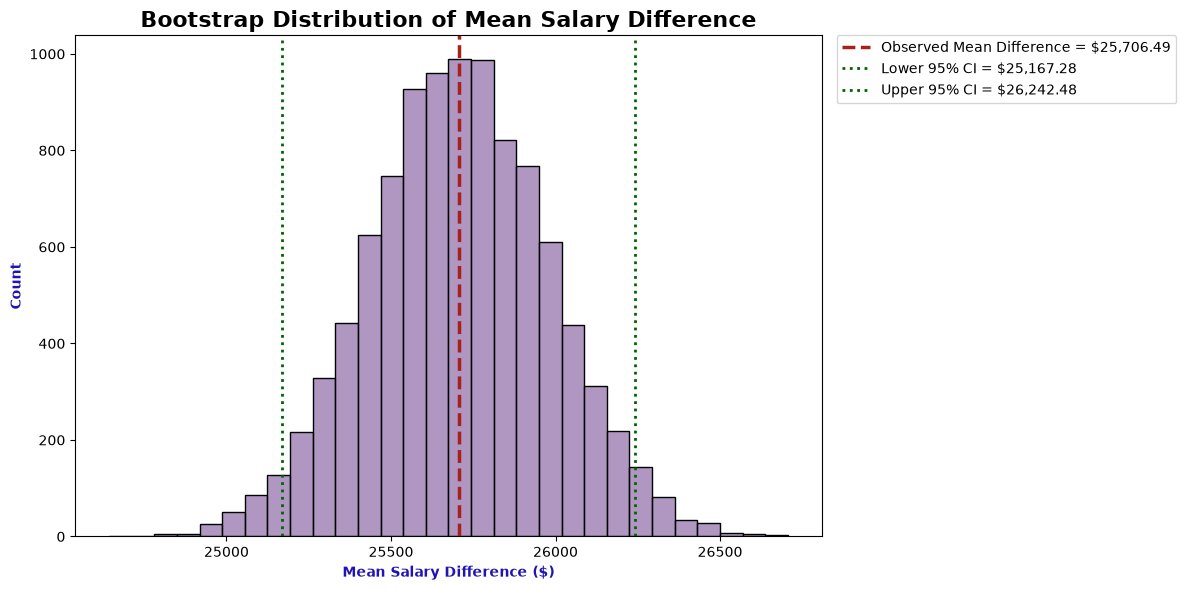

In [8]:
# 8. Plotting bootstrap distribution for mean difference

plt.figure(figsize=(12, 6))

sns.histplot(
    bootstrap_mean_differences,
    bins=30,
    color="#9474AD",
    edgecolor="black"
)

plt.axvline(
    observed_mean_difference,
    color="#A6201C",
    linestyle="--",
    linewidth=2.5,
    label=f"Observed Mean Difference = ${observed_mean_difference:,.2f}"
)

plt.axvline(
    mean_ci_lower,
    color="darkgreen",
    linestyle=":",
    linewidth=2,
    label=f"Lower 95% CI = ${mean_ci_lower:,.2f}"
)

plt.axvline(
    mean_ci_upper,
    color="darkgreen",
    linestyle=":",
    linewidth=2,
    label=f"Upper 95% CI = ${mean_ci_upper:,.2f}"
)

plt.title(
    "Bootstrap Distribution of Mean Salary Difference",
    fontweight="bold",
    fontsize=16
)

plt.xlabel(
    "Mean Salary Difference ($)",
    fontweight="bold",
    color="#2114B5"
)

plt.ylabel(
    "Count",
    fontweight="bold",
    color="#2114B5"
)

plt.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0
)

plt.tight_layout()

plt.show()

#### **Finding:**

*The bootstrap distribution of the mean salary difference is centered close to the observed difference of **`$25,706.49`**.*

*Most bootstrap mean differences fall between approximately **`$25,167.28`** and **`$26,242.48`**, which represents the 95% bootstrap confidence interval.*

*Because the entire confidence interval is above zero, the bootstrap results indicate that the mean salary difference between the Bachelor's Degree group and the High School Diploma or Equivalent group is consistently positive.*

### Median Salary Difference

The bootstrap distribution below shows the variability in the median salary difference across the 10,000 bootstrap resamples.

The median is especially important because the Central Limit Theorem does not directly provide the same simple standard error formula for the median as it does for the mean.

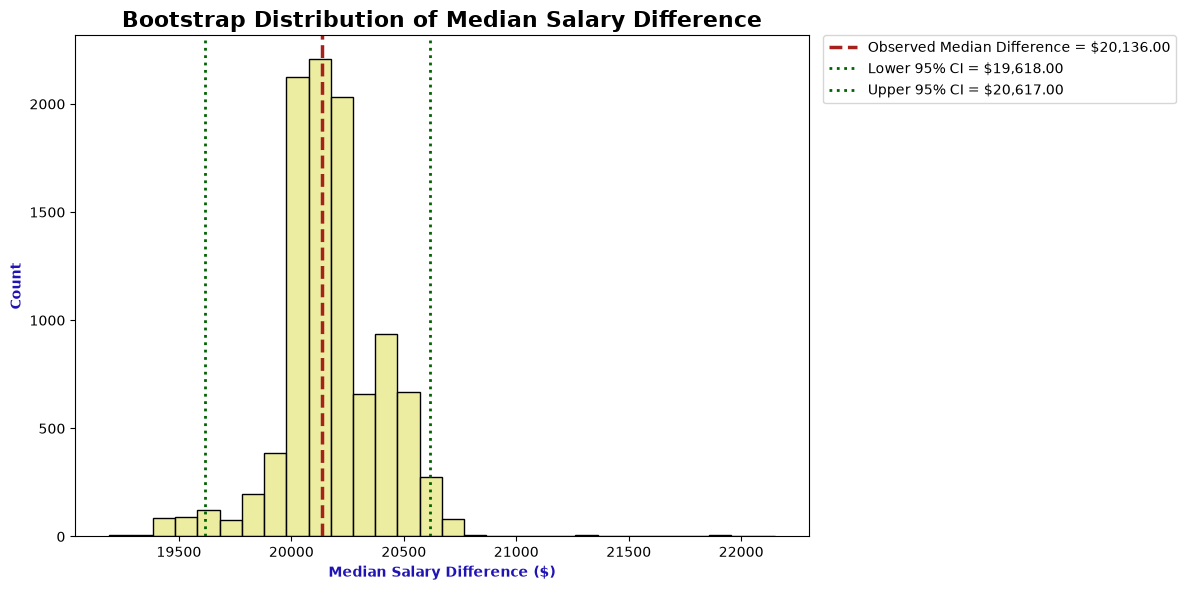

In [9]:
# 9. Plotting bootstrap distribution for median difference

plt.figure(figsize=(12, 6))

sns.histplot(
    bootstrap_median_differences,
    bins=30,
    color="#E6E880",
    edgecolor="black"
)

plt.axvline(
    observed_median_difference,
    color="#A6201C",
    linestyle="--",
    linewidth=2.5,
    label=f"Observed Median Difference = ${observed_median_difference:,.2f}"
)

plt.axvline(
    median_ci_lower,
    color="darkgreen",
    linestyle=":",
    linewidth=2,
    label=f"Lower 95% CI = ${median_ci_lower:,.2f}"
)

plt.axvline(
    median_ci_upper,
    color="darkgreen",
    linestyle=":",
    linewidth=2,
    label=f"Upper 95% CI = ${median_ci_upper:,.2f}"
)

plt.title(
    "Bootstrap Distribution of Median Salary Difference",
    fontweight="bold",
    fontsize=16
)

plt.xlabel(
    "Median Salary Difference ($)",
    fontweight="bold",
    color="#2114B5"
)

plt.ylabel(
    "Count",
    fontweight="bold",
    color="#2114B5"
)

plt.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0
)

plt.tight_layout()

plt.show()

#### **Finding:**

*The bootstrap distribution of the median salary difference is centered near the observed median difference of **`$20,136.00`**.*

*The 95% bootstrap confidence interval ranges from approximately **`$19,618.00`** to **`$20,617.00`**.*

*Because the entire confidence interval is above zero, the median salary for occupations requiring a Bachelor's Degree is consistently higher than the median salary for occupations requiring a High School Diploma or Equivalent across the bootstrap resamples.*

*The distribution is less smooth than the bootstrap distribution for the mean difference, which is expected because the median is more sensitive to the ordering of observations and does not rely on the Central Limit Theorem in the same way as the mean.*

## 6. Bootstrap Analysis Conclusion

The bootstrap analysis supports the same overall conclusion as the permutation test.

The 95% confidence interval for the mean salary difference is:

$$ [\$25{,}167.28,\ \$26{,}242.48] $$

The 95% confidence interval for the median salary difference is:

$$ [\$19{,}618.00,\ \$20{,}617.00] $$

Both intervals are entirely above zero, indicating that the salary difference between the Bachelor's Degree group and the High School Diploma or Equivalent group remains positive across repeated bootstrap samples.

The median-based interval is especially important because the Central Limit Theorem does not directly provide the same simple uncertainty estimate for the median. Bootstrapping therefore provides a practical way to quantify uncertainty for this non-CLT metric.